In [2]:

!pip install -q google-genai pymongo "pandas==2.2.3" "google-auth==2.49.0"


In [3]:

import google.genai
import pymongo
import pandas as pd

print("Gemini library: OK")
print("MongoDB library: OK")
print("Pandas version:", pd.__version__)


Gemini library: OK
MongoDB library: OK
Pandas version: 2.2.3


In [4]:

from google.colab import userdata

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")

if not GEMINI_API_KEY:
    raise ValueError("Gemini API key is missing!")

print("Gemini API key configured successfully!")


Gemini API key configured successfully!


In [9]:


from google import genai
from google.genai import types

client = genai.Client(
    api_key=GEMINI_API_KEY,
    http_options=types.HttpOptions(timeout=120000)
)

MODEL_NAME = "gemini-3.8-flash"

print("Gemini client updated successfully!")



Gemini client updated successfully!


In [11]:

from google import genai

models_client = genai.Client(api_key=GEMINI_API_KEY)

for model in models_client.models.list():
    print(model.name)


models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-omni-1.2-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/gemini-4-carbon
models/gemi

In [13]:

from google import genai
from google.genai import types

client = genai.Client(
    api_key=GEMINI_API_KEY,
    http_options=types.HttpOptions(timeout=120000)
)

MODEL_NAME = "gemini-3.5-flash-lite"

response = client.models.generate_content(
    model=MODEL_NAME,
    contents="Say only: Hello!"
)

print(response.text)


Hello!


In [20]:
from google.colab import userdata
from pymongo import MongoClient
from pymongo.server_api import ServerApi

MONGODB_URI = userdata.get("MONGODB_URI")

mongo_client = MongoClient(
    MONGODB_URI,
    server_api=ServerApi("1"),
    serverSelectionTimeoutMS=10000
)

print(mongo_client.admin.command("ping"))

{'ok': 1}


In [21]:

# Select the database
db = mongo_client["GenAI_Monitoring"]

# Create the collection for API usage logs
collection = db["api_usage_logs"]

# Create an index for faster searches by timestamp
collection.create_index("timestamp")

print("Database selected:", db.name)
print("Collection selected:", collection.name)
print("MongoDB setup completed successfully!")


Database selected: GenAI_Monitoring
Collection selected: api_usage_logs
MongoDB setup completed successfully!


In [22]:

import time
from datetime import datetime, timezone

def log_gemini_call(prompt):
    start_time = time.perf_counter()

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt
    )

    latency_ms = round((time.perf_counter() - start_time) * 1000, 2)

    usage = response.usage_metadata

    input_tokens = usage.prompt_token_count or 0
    output_tokens = usage.candidates_token_count or 0
    total_tokens = usage.total_token_count or 0

    log_record = {
        "timestamp": datetime.now(timezone.utc),
        "model": MODEL_NAME,
        "input_text": prompt,
        "output_text": response.text or "",
        "input_tokens": input_tokens,
        "output_tokens": output_tokens,
        "total_tokens": total_tokens,
        "latency_ms": latency_ms,
        "estimated_cost_usd": None,
        "status": "success"
    }

    collection.insert_one(log_record)

    print("Response:", response.text)
    print("Input tokens:", input_tokens)
    print("Output tokens:", output_tokens)
    print("Total tokens:", total_tokens)
    print("Latency (ms):", latency_ms)
    print("Log saved to MongoDB!")

print("Logging function created successfully!")


Logging function created successfully!


In [23]:

log_gemini_call("Explain Artificial Intelligence in two sentences.")


Response: Artificial Intelligence (AI) refers to computer systems designed to perform tasks that typically require human intelligence, such as learning, reasoning, problem-solving, and perception. By processing vast amounts of data and recognizing patterns, these systems can autonomously adapt, make decisions, and continuously improve their performance over time.
Input tokens: 8
Output tokens: 59
Total tokens: 67
Latency (ms): 4004.69
Log saved to MongoDB!


In [24]:

import pandas as pd

# Retrieve saved API call logs from MongoDB
logs = list(collection.find(
    {},
    {"_id": 0}
).sort("timestamp", -1))

df = pd.DataFrame(logs)

if not df.empty:
    display(df)
    print("Total API calls logged:", len(df))
else:
    print("No logs found. Run log_gemini_call() first.")


,timestamp,model,input_text,output_text,input_tokens,output_tokens,total_tokens,latency_ms,estimated_cost_usd,status
0,2026-11-13 06:03:38.731,gemini-3.5-flash-lite,Explain Artificial Intelligence in two sentences.,Artificial Intelligence (AI) refers to compute...,8,59,67,4004.69,None,success


Total API calls logged: 1


In [25]:

if not df.empty:
    print("Total API calls:", len(df))
    print("Total input tokens:", df["input_tokens"].sum())
    print("Total output tokens:", df["output_tokens"].sum())
    print("Total tokens:", df["total_tokens"].sum())
    print("Average latency (ms):", round(df["latency_ms"].mean(), 2))
    print("Maximum latency (ms):", round(df["latency_ms"].max(), 2))


Total API calls: 1
Total input tokens: 8
Total output tokens: 59
Total tokens: 67
Average latency (ms): 4004.69
Maximum latency (ms): 4004.69


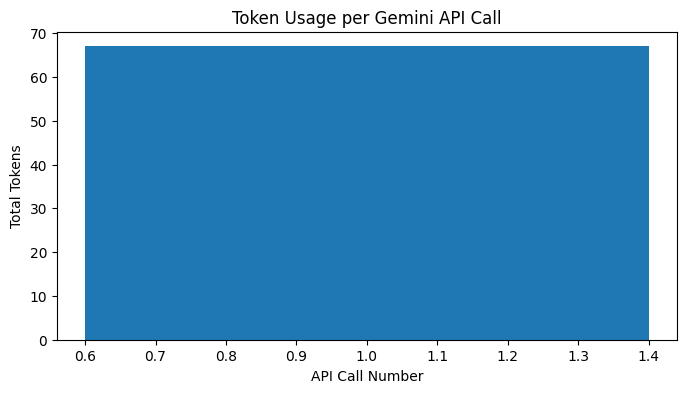

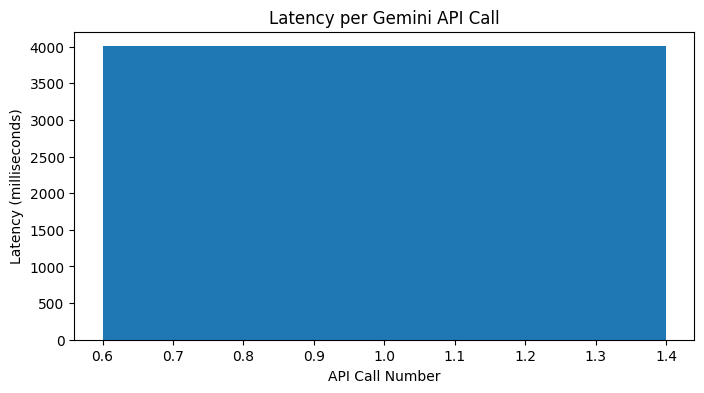

In [26]:
import matplotlib.pyplot as plt

if not df.empty:

    # Graph 1: Token usage
    plt.figure(figsize=(8, 4))
    plt.bar(range(1, len(df) + 1), df["total_tokens"])
    plt.xlabel("API Call Number")
    plt.ylabel("Total Tokens")
    plt.title("Token Usage per Gemini API Call")
    plt.show()

    # Graph 2: API response time
    plt.figure(figsize=(8, 4))
    plt.bar(range(1, len(df) + 1), df["latency_ms"])
    plt.xlabel("API Call Number")
    plt.ylabel("Latency (milliseconds)")
    plt.title("Latency per Gemini API Call")
    plt.show()

else:
    print("No logs found. Run log_gemini_call() first.")

In [28]:
print("Gemini model:", MODEL_NAME)

print("Input tokens used:", df["input_tokens"].sum())
print("Output tokens used:", df["output_tokens"].sum())
# Check the number of saved API calls
print("Total logs:", collection.count_documents({}))

# Show the latest 5 API call records
latest_logs = list(
    collection.find({}, {"_id": 0})
    .sort("timestamp", -1)
    .limit(5)
)

display(pd.DataFrame(latest_logs))

Gemini model: gemini-3.5-flash-lite
Input tokens used: 8
Output tokens used: 59
Total logs: 1


,timestamp,model,input_text,output_text,input_tokens,output_tokens,total_tokens,latency_ms,estimated_cost_usd,status
0,2026-11-13 06:03:38.731,gemini-3.5-flash-lite,Explain Artificial Intelligence in two sentences.,Artificial Intelligence (AI) refers to compute...,8,59,67,4004.69,None,success


In [29]:
import time
from datetime import datetime, timezone

def log_gemini_call_safe(prompt):
    start_time = time.perf_counter()

    try:
        response = client.models.generate_content(
            model=MODEL_NAME,
            contents=prompt
        )

        latency_ms = round(
            (time.perf_counter() - start_time) * 1000, 2
        )

        usage = response.usage_metadata

        record = {
            "timestamp": datetime.now(timezone.utc),
            "model": MODEL_NAME,
            "input_text": prompt,
            "output_text": response.text or "",
            "input_tokens": usage.prompt_token_count or 0,
            "output_tokens": usage.candidates_token_count or 0,
            "total_tokens": usage.total_token_count or 0,
            "latency_ms": latency_ms,
            "estimated_cost_usd": None,
            "status": "success",
            "error": None
        }

        collection.insert_one(record)
        print("API call successful!")
        print("Response:", response.text)
        print("Latency (ms):", latency_ms)
        print("Log saved to MongoDB!")

    except Exception as e:
        latency_ms = round(
            (time.perf_counter() - start_time) * 1000, 2
        )

        record = {
            "timestamp": datetime.now(timezone.utc),
            "model": MODEL_NAME,
            "input_text": prompt,
            "output_text": "",
            "input_tokens": 0,
            "output_tokens": 0,
            "total_tokens": 0,
            "latency_ms": latency_ms,
            "estimated_cost_usd": None,
            "status": "failed",
            "error": str(e)
        }

        collection.insert_one(record)
        print("API call failed.")
        print("Error:", e)
        print("Failure logged to MongoDB.")

print("Safe logging function created!")

Safe logging function created!


In [30]:
log_gemini_call_safe("Explain MongoDB in two simple sentences.")

API call successful!
Response: MongoDB is a flexible, document-based database that stores data in JSON-like formats rather than traditional tables and rows. It is designed to easily handle large volumes of rapidly changing, unstructured data while scaling efficiently.
Latency (ms): 646.32
Log saved to MongoDB!


In [31]:
import pandas as pd

# Fetch all API call logs from MongoDB
logs = list(
    collection.find({}, {"_id": 0})
    .sort("timestamp", -1)
)

df = pd.DataFrame(logs)

if not df.empty:
    print("===== GEMINI API MONITORING REPORT =====")
    print("Total API calls:", len(df))

    print("Successful calls:",
          (df["status"] == "success").sum())

    print("Failed calls:",
          (df["status"] == "failed").sum())

    print("Total input tokens:", df["input_tokens"].sum())
    print("Total output tokens:", df["output_tokens"].sum())
    print("Total tokens:", df["total_tokens"].sum())

    print("Average latency (ms):",
          round(df["latency_ms"].mean(), 2))

    print("\n===== RECENT API CALLS =====")
    display(df.head(10))

else:
    print("No API logs found.")

===== GEMINI API MONITORING REPORT =====
Total API calls: 2
Successful calls: 2
Failed calls: 0
Total input tokens: 16
Total output tokens: 101
Total tokens: 117
Average latency (ms): 2325.5

===== RECENT API CALLS =====


,timestamp,model,input_text,output_text,input_tokens,output_tokens,total_tokens,latency_ms,estimated_cost_usd,status,error
0,2026-11-13 06:05:48.098,gemini-3.5-flash-lite,Explain MongoDB in two simple sentences.,"MongoDB is a flexible, document-based database...",8,42,50,646.32,None,success,NaN
1,2026-11-13 06:03:38.731,gemini-3.5-flash-lite,Explain Artificial Intelligence in two sentences.,Artificial Intelligence (AI) refers to compute...,8,59,67,4004.69,None,success,NaN


**Conclusion**

The practical successfully demonstrates monitoring Gemini API calls using Python and MongoDB. Each API call is logged with its timestamp, model name, input and output text, token usage, latency, and status. MongoDB stores the records for later analysis. Pandas is used to summarize API usage, while Matplotlib visualizes token consumption and response time. Error handling is also implemented to record failed API calls. This system helps monitor API usage and provides a foundation for estimating API costs.